Generating sample medical image batch...

--- Phase 1: Training Top Classification Head ---
Epoch 1/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.5250 - loss: 0.7202 - val_accuracy: 0.5000 - val_loss: 0.7080
Epoch 2/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.7250 - loss: 0.5436 - val_accuracy: 0.3250 - val_loss: 0.7731
Epoch 3/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.7875 - loss: 0.4681 - val_accuracy: 0.3750 - val_loss: 1.0008

--- Phase 2: Fine-Tuning Top Inception Blocks ---
Epoch 1/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.5437 - loss: 2.3931 - val_accuracy: 0.3750 - val_loss: 0.9470
Epoch 2/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.7750 - loss: 0.6944 - val_accuracy: 0.4500 - val_loss: 0.7701
Epoch 3/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.9563 - loss: 0.1111 - val_accuracy: 0.5000 - val_loss: 0.7319
Epoch 4/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.9812 - loss: 0.0912 - val_accuracy: 0.5000 -

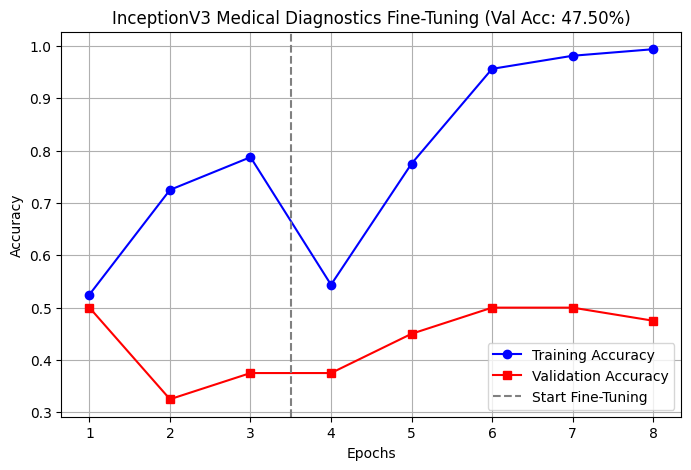

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.inception_v3 import InceptionV3
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import SGD, Adam
import numpy as np
import matplotlib.pyplot as plt

# =========================================================================
# 1. Create Synthetic Medical Image Data
# =========================================================================
print("Generating sample medical image batch...")
# 200 sample images (150x150 RGB) for 2 classes (e.g., Normal vs Abnormal)
X_train = np.random.rand(160, 150, 150, 3).astype('float32')
y_train = tf.keras.utils.to_categorical(np.random.randint(0, 2, 160), 2)

X_val = np.random.rand(40, 150, 150, 3).astype('float32')
y_val = tf.keras.utils.to_categorical(np.random.randint(0, 2, 40), 2)

# =========================================================================
# 2. Build InceptionV3 Base Model (Tutorial Setup)
# =========================================================================
base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=(150, 150, 3))

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)
x = Dropout(0.2)(x)
predictions = Dense(2, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

# Freeze base layers for initial top-layer training
for layer in base_model.layers:
    layer.trainable = False

model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

# =========================================================================
# 3. Phase 1: Train Top Layers (Warm-up)
# =========================================================================
print("\n--- Phase 1: Training Top Classification Head ---")
history_warmup = model.fit(
    X_train, y_train,
    epochs=3,
    batch_size=16,
    validation_data=(X_val, y_val)
)

# =========================================================================
# 4. Phase 2: Fine-Tune Top Convolutional Inception Blocks
# =========================================================================
print("\n--- Phase 2: Fine-Tuning Top Inception Blocks ---")
# Freeze first 249 layers, unfreeze remaining top blocks (matching tutorial)
for layer in model.layers[:249]:
    layer.trainable = False
for layer in model.layers[249:]:
    layer.trainable = True

model.compile(optimizer=SGD(learning_rate=0.0001, momentum=0.9), loss='categorical_crossentropy', metrics=['accuracy'])

history_finetune = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=16,
    validation_data=(X_val, y_val)
)

# =========================================================================
# 5. Plot Deliverable Graphs (Assignment Requirement)
# =========================================================================
val_loss, val_acc = model.evaluate(X_val, y_val)
print(f"\nFinal Validation Accuracy: {val_acc * 100:.2f}%")

total_train_acc = history_warmup.history['accuracy'] + history_finetune.history['accuracy']
total_val_acc = history_warmup.history['val_accuracy'] + history_finetune.history['val_accuracy']
epochs_range = range(1, len(total_train_acc) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, total_train_acc, 'b-o', label='Training Accuracy')
plt.plot(epochs_range, total_val_acc, 'r-s', label='Validation Accuracy')
plt.axvline(x=3.5, color='gray', linestyle='--', label='Start Fine-Tuning')
plt.title(f'InceptionV3 Medical Diagnostics Fine-Tuning (Val Acc: {val_acc*100:.2f}%)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()